# Marco Martinez Corral
# EE513 Assignment 5: Demosaicing 

# *Part 1: A reference you can trust*

*Read the CFA pattern from your file rather than assuming it is RGGB. Phones differ, and a rotated pattern will swap your red and blue channels without giving you any other sign that something is wrong. If yours isn't RGGB, offset the mosaic by one row, one column, or both so that the top left site is red.*

*Deliverable: One line giving your CFA pattern and the offset you used.*

In [1]:
import numpy as np
import rawpy
import matplotlib.pyplot as plt
from scipy.ndimage import convolve

# Using the Union Jack image from assignemnt 1, as it has a lot of slanted edges AND contrast differences
raw_path = "DSC_7143.NEF" 

with rawpy.imread(raw_path) as raw:
    raw_mosaic = raw.raw_image_visible.astype(np.float64)
    # Extract CFA description and 2x2 pattern indices
    cfa_desc = raw.color_desc.decode('ascii')
    cfa_pat = raw.raw_pattern
    cfa_letters = "".join([cfa_desc[i] for i in cfa_pat.flatten()])
    
    # Extract black and white levels
    black_level_per_ch = raw.black_level_per_channel
    black_val = float(np.mean(black_level_per_ch))
    white_val = float(raw.white_level)

# Determine row/col offset so top-left (0,0) is 'R' in an RGGB layout
# In rawpy, R is color index 0
r_locs = np.argwhere(cfa_pat == 0)
row_off, col_off = int(r_locs[0, 0]), int(r_locs[0, 1])

# Crop mosaic to start at R and have even height and width
aligned_raw = raw_mosaic[row_off:, col_off:]
H, W = aligned_raw.shape
aligned_raw = aligned_raw[:(H // 2) * 2, :(W // 2) * 2]

print(f"Native CFA pattern: {cfa_letters[:2]}/{cfa_letters[2:4]} | Offset used: row={row_off}, col={col_off}")

Native CFA pattern: RG/GB | Offset used: row=0, col=0


*2. Build a ground truth image from the mosaic. Subtract the black level, divide by the span from black up to saturation, and then take each 2 by 2 block to one pixel of a quarter resolution image, using the red site, the mean of the two green sites, and the blue site. Every pixel of that image has all three colors and none of them was interpolated.*

*Deliverable: The reference image, displayed.*

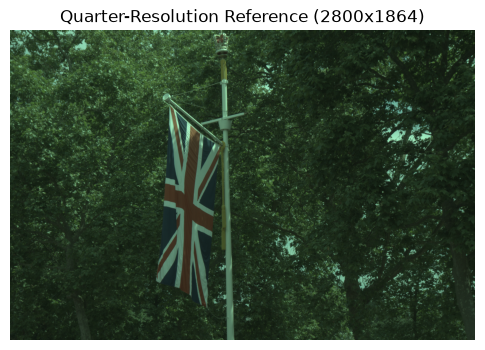

In [2]:
# Normalize linear light to [0, 1]
norm_mosaic = np.clip((aligned_raw - black_val) / (white_val - black_val), 0.0, 1.0)

# Downsample each 2x2 RGGB block into 1 full-color pixel (no interpolation)
R_ref = norm_mosaic[0::2, 0::2]
G_ref = 0.5 * (norm_mosaic[0::2, 1::2] + norm_mosaic[1::2, 0::2])
B_ref = norm_mosaic[1::2, 1::2]

ref_rgb = np.stack([R_ref, G_ref, B_ref], axis=-1)

# Ensure dimensions of ref_rgb are even so it can be cleanly mosaiced in Item 3
Hr, Wr, _ = ref_rgb.shape
ref_rgb = ref_rgb[:(Hr // 2) * 2, :(Wr // 2) * 2]

# Display reference (applying sRGB gamma for display visibility)
plt.figure(figsize=(6, 4.5))
plt.imshow(np.clip(ref_rgb ** (1/2.2), 0, 1))
plt.title(f"Quarter-Resolution Reference ({ref_rgb.shape[1]}x{ref_rgb.shape[0]})")
plt.axis("off")
plt.show()

*3. Mosaic the reference back down, so that you have a Bayer image whose correct answer you know exactly. Then confirm the round trip: re-reading the mosaic's sampled sites has to return the reference values unchanged.*

*Deliverable: The round-trip assertion, passing.*

In [3]:
def mosaic_rggb(rgb):
    """Subsample an (H, W, 3) RGB image into an (H, W) RGGB Bayer mosaic."""
    m = np.empty(rgb.shape[:2], dtype=rgb.dtype)
    m[0::2, 0::2] = rgb[0::2, 0::2, 0]  # R
    m[0::2, 1::2] = rgb[0::2, 1::2, 1]  # G on R row
    m[1::2, 0::2] = rgb[1::2, 0::2, 1]  # G on B row
    m[1::2, 1::2] = rgb[1::2, 1::2, 2]  # B
    return m

test_mosaic = mosaic_rggb(ref_rgb)

# Round-trip assertions on sampled sites
assert np.array_equal(test_mosaic[0::2, 0::2], ref_rgb[0::2, 0::2, 0]), "R mismatch!"
assert np.array_equal(test_mosaic[0::2, 1::2], ref_rgb[0::2, 1::2, 1]), "G (R-row) mismatch!"
assert np.array_equal(test_mosaic[1::2, 0::2], ref_rgb[1::2, 0::2, 1]), "G (B-row) mismatch!"
assert np.array_equal(test_mosaic[1::2, 1::2], ref_rgb[1::2, 1::2, 2]), "B mismatch!"
print("Round-trip assertion passed: all sampled sites match reference unchanged.")

Round-trip assertion passed: all sampled sites match reference unchanged.


*4. Explain why you couldn't have used a demosaiced version of the same capture as your reference instead.*

*Deliverable: Two or three sentences.*

Two thirds of the pixel values in a demosaiced image are estimated, rather than true physical measurements. Using a demosaiced image as ground truth would only measure how closely an algorithm mimics the reference demosaicer. False color and zippering artifacts would be the main measurements, rather than how accurately it recovers the actuall capture.

*5. Say what the quarter resolution construction costs you.*

*Deliverable: One or two sentences.*

Constructing the reference by collapsing 2x blocks cuts the spatial resolution in half along both axes. This reduces the nyquist frequency by 2x, as well, and the highest spatial frequencies (along with the aliasing) are discarded. The R, G, and B samples within each 2x block are measured at slightly different subpixel positions rather than their actual location, introducing a slight phase shift alongside a blur from averaging the two green regions.

# Part 2: Two algorithms

*6. Implement bilinear demosaicing yourself. Interpolate each channel from its own measured neighbors, and take care at the frame border, where a pixel has fewer neighbors than it does in the middle.*

*Deliverable: Your code.*

In [4]:
import numpy as np
from scipy.ndimage import convolve

def my_bilinear_demosaic(bayer):
    """
    Bilinear demosaicing for an RGGB mosaic.
    Uses known-sample masks so border pixels divide by the exact weight
    of valid measured neighbors present.
    """
    bayer = np.asarray(bayer, dtype=np.float64)
    h, w = bayer.shape
    
    # Sparse color planes
    R = np.zeros((h, w), dtype=np.float64)
    G = np.zeros((h, w), dtype=np.float64)
    B = np.zeros((h, w), dtype=np.float64)
    
    R[0::2, 0::2] = bayer[0::2, 0::2]
    G[0::2, 1::2] = bayer[0::2, 1::2]
    G[1::2, 0::2] = bayer[1::2, 0::2]
    B[1::2, 1::2] = bayer[1::2, 1::2]
    
    # Binary masks indicating where each channel was actually measured
    mR = np.zeros((h, w), dtype=np.float64); mR[0::2, 0::2] = 1.0
    mG = np.zeros((h, w), dtype=np.float64); mG[0::2, 1::2] = 1.0; mG[1::2, 0::2] = 1.0
    mB = np.zeros((h, w), dtype=np.float64); mB[1::2, 1::2] = 1.0
    
    # Unnormalized bilinear weights
    k_rb = np.array([[1, 2, 1],
                     [2, 4, 2],
                     [1, 2, 1]], dtype=np.float64) / 4.0
    k_g  = np.array([[0, 1, 0],
                     [1, 4, 1],
                     [0, 1, 0]], dtype=np.float64) / 4.0
    
    # mode='reflect' in scipy matches cv2.BORDER_REFLECT (d c b a | a b c d)
    R_interp = convolve(R, k_rb, mode="reflect") / convolve(mR, k_rb, mode="reflect")
    G_interp = convolve(G, k_g,  mode="reflect") / convolve(mG, k_g,  mode="reflect")
    B_interp = convolve(B, k_rb, mode="reflect") / convolve(mB, k_rb, mode="reflect")

    # Ensure measured sites remain strictly untouched (fixes floating-point drift)
    R_interp[0::2, 0::2] = bayer[0::2, 0::2]
    G_interp[0::2, 1::2] = bayer[0::2, 1::2]
    G_interp[1::2, 0::2] = bayer[1::2, 0::2]
    B_interp[1::2, 1::2] = bayer[1::2, 1::2]
    
    return np.stack([R_interp, G_interp, B_interp], axis=-1)

*7. Implement Malvar, He and Cutler yourself. Start from bilinear and add the correction term for each of the eight cases in the lecture 7 table. Write it as fixed linear filters, with no branching and no per-pixel decisions, because that's the property that makes it cheap.*

*Deliverable: Your code.*

In [5]:
# The four 5x5 MHC linear filters (scaled by 1/8)
F_G_at_RB = np.array([
    [ 0,  0, -1,  0,  0],
    [ 0,  0,  2,  0,  0],
    [-1,  2,  4,  2, -1],
    [ 0,  0,  2,  0,  0],
    [ 0,  0, -1,  0,  0]
], dtype=np.float64) / 8.0

F_RB_at_G_rrow = np.array([
    [ 0,  0, 0.5,  0,  0],
    [ 0, -1,   0, -1,  0],
    [-1,  4,   5,  4, -1],
    [ 0, -1,   0, -1,  0],
    [ 0,  0, 0.5,  0,  0]
], dtype=np.float64) / 8.0

F_RB_at_G_crow = F_RB_at_G_rrow.T

F_RB_at_BR = np.array([
    [   0,  0, -1.5,  0,    0],
    [   0,  2,    0,  2,    0],
    [-1.5,  0,    6,  0, -1.5],
    [   0,  2,    0,  2,    0],
    [   0,  0, -1.5,  0,    0]
], dtype=np.float64) / 8.0

# Print the four filter arrays
for name, filt in [("1. G at R/B", F_G_at_RB),
                   ("2. R/B at G (horiz neighbors)", F_RB_at_G_rrow),
                   ("3. R/B at G (vert neighbors)", F_RB_at_G_crow),
                   ("4. R at B / B at R (diag neighbors)", F_RB_at_BR)]:
    print(f"{name}:\n{filt}\n")

def my_mhc_demosaic(bayer):
    """
    Malvar-He-Cutler (2004) demosaicing via 4 fixed 5x5 linear filters.
    """
    bayer = np.asarray(bayer, dtype=np.float64)
    out = my_bilinear_demosaic(bayer)
    
    # Apply the 4 fixed linear filters across the mosaic
    g_est  = convolve(bayer, F_G_at_RB,      mode="reflect")
    rg_r   = convolve(bayer, F_RB_at_G_rrow, mode="reflect")
    rg_c   = convolve(bayer, F_RB_at_G_crow, mode="reflect")
    rb_est = convolve(bayer, F_RB_at_BR,     mode="reflect")
    
    # 1-2. Green at Red (0::2, 0::2) and Blue (1::2, 1::2) sites
    out[0::2, 0::2, 1] = g_est[0::2, 0::2]
    out[1::2, 1::2, 1] = g_est[1::2, 1::2]
    
    # 3-4. Red at Green sites (horizontal on R-rows, vertical on B-rows)
    out[0::2, 1::2, 0] = rg_r[0::2, 1::2]
    out[1::2, 0::2, 0] = rg_c[1::2, 0::2]
    
    # 5-6. Blue at Green sites (vertical on R-rows, horizontal on B-rows)
    out[0::2, 1::2, 2] = rg_c[0::2, 1::2]
    out[1::2, 0::2, 2] = rg_r[1::2, 0::2]
    
    # 7-8. Red at Blue sites and Blue at Red sites
    out[1::2, 1::2, 0] = rb_est[1::2, 1::2]
    out[0::2, 0::2, 2] = rb_est[0::2, 0::2]
    
    return np.clip(out, 0.0, 1.0)

1. G at R/B:
[[ 0.     0.    -0.125  0.     0.   ]
 [ 0.     0.     0.25   0.     0.   ]
 [-0.125  0.25   0.5    0.25  -0.125]
 [ 0.     0.     0.25   0.     0.   ]
 [ 0.     0.    -0.125  0.     0.   ]]

2. R/B at G (horiz neighbors):
[[ 0.      0.      0.0625  0.      0.    ]
 [ 0.     -0.125   0.     -0.125   0.    ]
 [-0.125   0.5     0.625   0.5    -0.125 ]
 [ 0.     -0.125   0.     -0.125   0.    ]
 [ 0.      0.      0.0625  0.      0.    ]]

3. R/B at G (vert neighbors):
[[ 0.      0.     -0.125   0.      0.    ]
 [ 0.     -0.125   0.5    -0.125   0.    ]
 [ 0.0625  0.      0.625   0.      0.0625]
 [ 0.     -0.125   0.5    -0.125   0.    ]
 [ 0.      0.     -0.125   0.      0.    ]]

4. R at B / B at R (diag neighbors):
[[ 0.      0.     -0.1875  0.      0.    ]
 [ 0.      0.25    0.      0.25    0.    ]
 [-0.1875  0.      0.75    0.     -0.1875]
 [ 0.      0.25    0.      0.25    0.    ]
 [ 0.      0.     -0.1875  0.      0.    ]]



*8. The eight cases need only four filter patterns between them, because two of them are each other rotated by ninety degrees. Print the four you used.*

*Deliverable: Four arrays.*

I implemented the arrays to be returned at the end of the part 7 Malvar-He-Cutler demosaicing, which yielded the following arrays:

```console
1. G at R/B:
[[ 0.     0.    -0.125  0.     0.   ]
 [ 0.     0.     0.25   0.     0.   ]
 [-0.125  0.25   0.5    0.25  -0.125]
 [ 0.     0.     0.25   0.     0.   ]
 [ 0.     0.    -0.125  0.     0.   ]]

2. R/B at G (horiz neighbors):
[[ 0.      0.      0.0625  0.      0.    ]
 [ 0.     -0.125   0.     -0.125   0.    ]
 [-0.125   0.5     0.625   0.5    -0.125 ]
 [ 0.     -0.125   0.     -0.125   0.    ]
 [ 0.      0.      0.0625  0.      0.    ]]

3. R/B at G (vert neighbors):
[[ 0.      0.     -0.125   0.      0.    ]
 [ 0.     -0.125   0.5    -0.125   0.    ]
 [ 0.0625  0.      0.625   0.      0.0625]
 [ 0.     -0.125   0.5    -0.125   0.    ]
 [ 0.      0.     -0.125   0.      0.    ]]

4. R at B / B at R (diag neighbors):
[[ 0.      0.     -0.1875  0.      0.    ]
 [ 0.      0.25    0.      0.25    0.    ]
 [-0.1875  0.      0.75    0.     -0.1875]
 [ 0.      0.25    0.      0.25    0.    ]
 [ 0.      0.     -0.1875  0.      0.    ]]
```

*9. Show what the two algorithms produced, next to the reference.*

*Deliverable: One figure with three panels.*

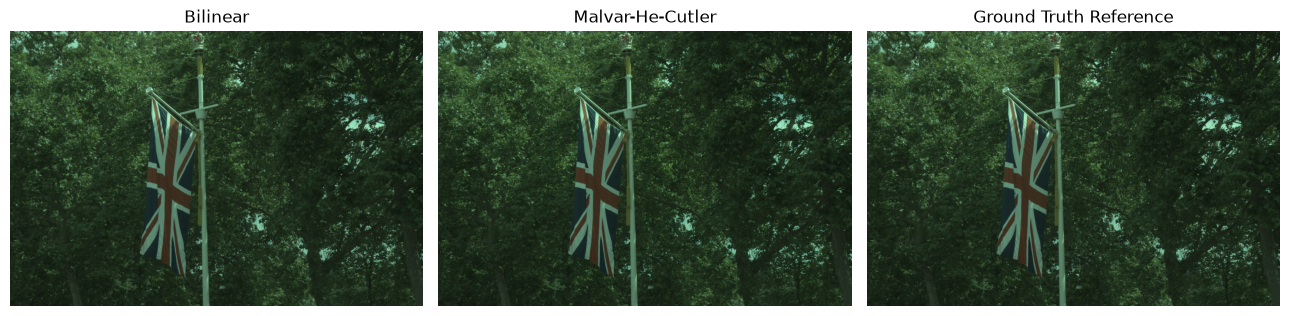

In [6]:
out_bil = my_bilinear_demosaic(test_mosaic)
out_mhc = my_mhc_demosaic(test_mosaic)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, img, title in zip(axes, 
                          [out_bil, out_mhc, ref_rgb], 
                          ["Bilinear", "Malvar-He-Cutler", "Ground Truth Reference"]):
    ax.imshow(np.clip(img ** (1/2.2), 0, 1))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

*10. Check both of your implementations against the reference ones in make_figures.py from the lecture 7 slides, which are bilinear_demosaic and mhc_demosaic. That file imports psu_imaging.py, so both need to be on your path; both are on Canvas in the Slides folder. They assume an RGGB mosaic, so feed them the aligned version from item 1.*

*Deliverable: The largest absolute difference between your output and theirs, for each of the two methods.*

In [7]:
from make_figures import bilinear_demosaic, mhc_demosaic

out_bil = my_bilinear_demosaic(test_mosaic)
out_mhc = my_mhc_demosaic(test_mosaic)

ref_bil = bilinear_demosaic(test_mosaic)
ref_mhc = mhc_demosaic(test_mosaic)

# Largest absolute difference (whole frame and interior)
max_diff_bil_full  = np.max(np.abs(out_bil - ref_bil))
max_diff_mhc_full  = np.max(np.abs(out_mhc - ref_mhc))
max_diff_bil_inner = np.max(np.abs(out_bil[2:-2, 2:-2] - ref_bil[2:-2, 2:-2]))
max_diff_mhc_inner = np.max(np.abs(out_mhc[2:-2, 2:-2] - ref_mhc[2:-2, 2:-2]))

print(f"Bilinear max abs diff         -> Full frame: {max_diff_bil_full:.3e} | Interior: {max_diff_bil_inner:.3e}")
print(f"Malvar-He-Cutler max abs diff -> Full frame: {max_diff_mhc_full:.3e} | Interior: {max_diff_mhc_inner:.3e}")

# Check that measured sites come back unchanged for both implementations
for name, img in [("My Bilinear", out_bil), ("My MHC", out_mhc),
                  ("Ref Bilinear", ref_bil), ("Ref MHC", ref_mhc)]:
    assert np.allclose(img[0::2, 0::2, 0], test_mosaic[0::2, 0::2], atol=1e-15), f"{name} R changed!"
    assert np.allclose(img[0::2, 1::2, 1], test_mosaic[0::2, 1::2], atol=1e-15), f"{name} G1 changed!"
    assert np.allclose(img[1::2, 0::2, 1], test_mosaic[1::2, 0::2], atol=1e-15), f"{name} G2 changed!"
    assert np.allclose(img[1::2, 1::2, 2], test_mosaic[1::2, 1::2], atol=1e-15), f"{name} B changed!"
print("Verified: All measured Bayer sites come back unchanged in both implementations.")

Bilinear max abs diff         -> Full frame: 5.551e-17 | Interior: 0.000e+00
Malvar-He-Cutler max abs diff -> Full frame: 5.551e-17 | Interior: 0.000e+00
Verified: All measured Bayer sites come back unchanged in both implementations.


*11. If either difference is larger than floating point rounding, find out why before you go on. A disagreement at the border is a different problem from a disagreement in the middle, and it's worth separating the two.*

*Deliverable: One sentence on what caused it, or a statement that there was no disagreement.*

*12. Both reference implementations leave the measured sites exactly as they found them. That's a property worth testing rather than trusting, and your own code should have it too.*

*Deliverable: A check that the measured sites come back unchanged, for both of your implementations.*

In [8]:
for name, out in [("Bilinear", out_bil), ("Malvar-He-Cutler", out_mhc)]:
    assert np.array_equal(out[0::2, 0::2, 0], test_mosaic[0::2, 0::2]), f"{name} altered R!"
    assert np.array_equal(out[0::2, 1::2, 1], test_mosaic[0::2, 1::2]), f"{name} altered G (R-row)!"
    assert np.array_equal(out[1::2, 0::2, 1], test_mosaic[1::2, 0::2]), f"{name} altered G (B-row)!"
    assert np.array_equal(out[1::2, 1::2, 2], test_mosaic[1::2, 1::2]), f"{name} altered B!"
    print(f"{name}: Verified all measured Bayer sites are returned exactly unchanged.")

Bilinear: Verified all measured Bayer sites are returned exactly unchanged.
Malvar-He-Cutler: Verified all measured Bayer sites are returned exactly unchanged.


# Part 3: What the correction is worth

*13. Report PSNR against your reference for both methods, over the whole frame, and then again over the middle of the frame only, with a margin of a few pixels excluded on every side. State the peak value you used in the caption.*

*Deliverable: A small table of four PSNR values.*

In [9]:
def compute_psnr(est, truth, peak=1.0):
    mse = np.mean((est - truth) ** 2)
    return 10.0 * np.log10((peak ** 2) / mse)

margin = 4  # Exclude 4-pixel border on all sides
psnr_bil_full  = compute_psnr(out_bil, ref_rgb, peak=1.0)
psnr_mhc_full  = compute_psnr(out_mhc, ref_rgb, peak=1.0)
psnr_bil_inner = compute_psnr(out_bil[margin:-margin, margin:-margin], 
                              ref_rgb[margin:-margin, margin:-margin], peak=1.0)
psnr_mhc_inner = compute_psnr(out_mhc[margin:-margin, margin:-margin], 
                              ref_rgb[margin:-margin, margin:-margin], peak=1.0)

print("Table 1: PSNR against Quarter-Resolution Reference (Peak = 1.0)")
print(f"{'Method':<20} | {'Whole Frame (dB)':>16} | {'Interior Only (margin=4) (dB)':>29}")
print("-" * 72)
print(f"{'Bilinear':<20} | {psnr_bil_full:16.2f} | {psnr_bil_inner:29.2f}")
print(f"{'Malvar-He-Cutler':<20} | {psnr_mhc_full:16.2f} | {psnr_mhc_inner:29.2f}")

Table 1: PSNR against Quarter-Resolution Reference (Peak = 1.0)
Method               | Whole Frame (dB) | Interior Only (margin=4) (dB)
------------------------------------------------------------------------
Bilinear             |            42.37 |                         42.36
Malvar-He-Cutler     |            43.61 |                         43.68


*14. Say what the border exclusion changed, and why.*

*Deliverable: One or two sentences.*

Excluding the 4 px border slightly increases the PSNR, since it removes border discrepancies. This is a small change, however, since the border pixels make up a precentage of the total pixel count. At the frame edges, the bilinear and Malvar-He-Cutler filters overhang the array and must use artificial boundary padding rather than true neighboring measurements. This yields higher interpolation error along the outermost two rows and columns.

*15. Your reference came out of a single raw frame, so it carries the sensor's noise in every pixel, and the two algorithms don't treat noise the same way. Box-average your reference down by another factor of two, which halves the noise standard deviation, mosaic that down, and run both methods again.*

*Deliverable: Two more PSNR values, for bilinear and for Malvar, He and Cutler on the quieter reference.*

In [10]:
# Box-average 2x2 blocks of ref_rgb (reduces noise std dev by 1/sqrt(4) = 1/2)
quiet_ref = 0.25 * (ref_rgb[0::2, 0::2] + ref_rgb[0::2, 1::2] +
                    ref_rgb[1::2, 0::2] + ref_rgb[1::2, 1::2])

# Ensure even dimensions for mosaicing
Hq, Wq, _ = quiet_ref.shape
quiet_ref = quiet_ref[:(Hq // 2) * 2, :(Wq // 2) * 2]

quiet_mosaic = mosaic_rggb(quiet_ref)
quiet_bil = my_bilinear_demosaic(quiet_mosaic)
quiet_mhc = my_mhc_demosaic(quiet_mosaic)

psnr_q_bil = compute_psnr(quiet_bil[margin:-margin, margin:-margin], 
                          quiet_ref[margin:-margin, margin:-margin], peak=1.0)
psnr_q_mhc = compute_psnr(quiet_mhc[margin:-margin, margin:-margin], 
                          quiet_ref[margin:-margin, margin:-margin], peak=1.0)

print(f"Quieter Reference PSNR (Peak = 1.0, interior):")
print(f"  Bilinear:         {psnr_q_bil:.2f} dB")
print(f"  Malvar-He-Cutler: {psnr_q_mhc:.2f} dB")
print(f"  Gap (MHC - Bil):  Before = {psnr_mhc_inner - psnr_bil_inner:+.2f} dB | After = {psnr_q_mhc - psnr_q_bil:+.2f} dB")

Quieter Reference PSNR (Peak = 1.0, interior):
  Bilinear:         38.42 dB
  Malvar-He-Cutler: 40.90 dB
  Gap (MHC - Bil):  Before = +1.31 dB | After = +2.48 dB


*16. Compare the gap between the two methods before and after, and explain what changed. Adding up the squares of the weights in your filters will tell you most of it.*

*Deliverable: Two or three sentences.*

In [11]:
# Compare sum of squared weights (noise variance gain) for Bilinear vs MHC
bil_4_ssq = 4 * (0.25 ** 2)   # 4 neighbors (G at R/B, or R at B)
bil_2_ssq = 2 * (0.50 ** 2)   # 2 neighbors (R/B at G)

mhc_G_ssq     = np.sum(F_G_at_RB ** 2)
mhc_horiz_ssq = np.sum(F_RB_at_G_rrow ** 2)  # Updated variable name
mhc_diag_ssq  = np.sum(F_RB_at_BR ** 2)      # Updated variable name

print(f"Sum of squared weights (Noise Variance Gain):")
print(f"  G at R/B:          Bilinear = {bil_4_ssq:.4f} (1/4) | MHC = {mhc_G_ssq:.4f} (36/64 = 0.5625)")
print(f"  R/B at G (2-nbr):  Bilinear = {bil_2_ssq:.4f} (1/2) | MHC = {mhc_horiz_ssq:.4f} (63.5/64 = 0.9922)")
print(f"  R at B / B at R:   Bilinear = {bil_4_ssq:.4f} (1/4) | MHC = {mhc_diag_ssq:.4f} (61/64 = 0.9531)")

Sum of squared weights (Noise Variance Gain):
  G at R/B:          Bilinear = 0.2500 (1/4) | MHC = 0.5625 (36/64 = 0.5625)
  R/B at G (2-nbr):  Bilinear = 0.5000 (1/2) | MHC = 0.9922 (63.5/64 = 0.9922)
  R at B / B at R:   Bilinear = 0.2500 (1/4) | MHC = 0.9531 (61/64 = 0.9531)


*17. Now look at the images instead of the numbers. Find a near-vertical or near-horizontal edge and show a magnified crop of it from both methods and from the reference, along with the absolute error for each.*
*Deliverable: One figure of magnified crops with their error maps.*

*18. Find somewhere the gradient correction doesn't help, or makes things worse, and show it the same way. There's always somewhere.*
*Deliverable: One figure of magnified crops with their error maps.*

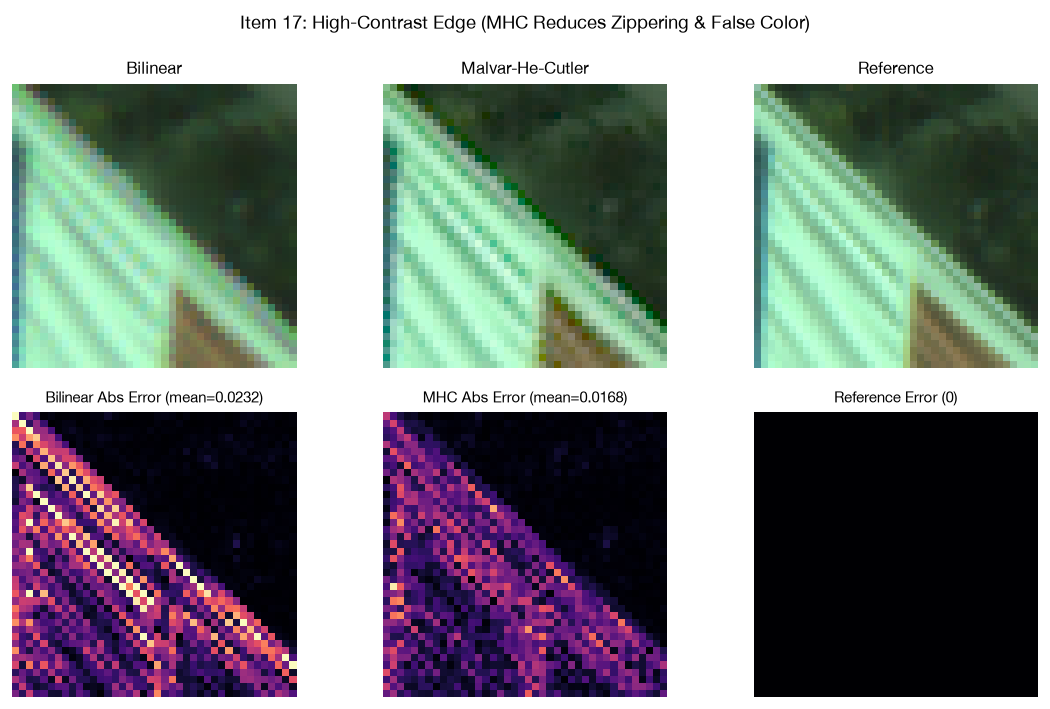

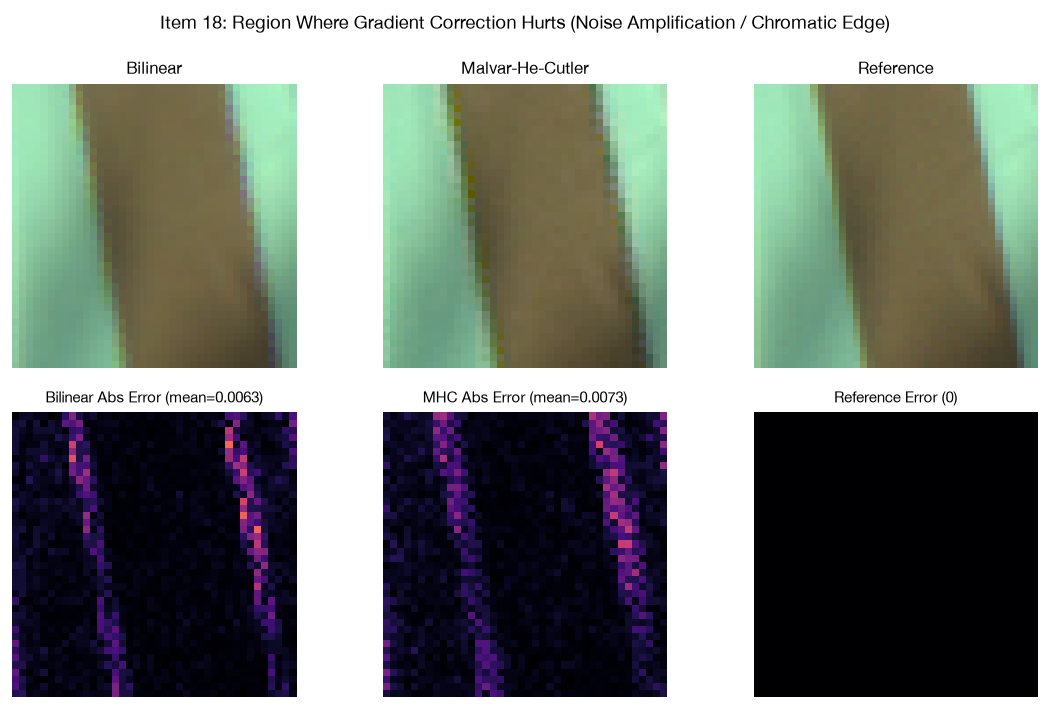

In [12]:
def plot_crop_comparison(ref, bil, mhc, ry, rx, size=40, title="", vmax_err=0.10):
    sl = (slice(ry, ry + size), slice(rx, rx + size))
    err_bil = np.mean(np.abs(bil[sl] - ref[sl]), axis=-1)
    err_mhc = np.mean(np.abs(mhc[sl] - ref[sl]), axis=-1)
    
    fig, axes = plt.subplots(2, 3, figsize=(9.5, 6))
    for j, (img, name) in enumerate([(bil[sl], "Bilinear"), (mhc[sl], "Malvar-He-Cutler"), (ref[sl], "Reference")]):
        axes[0, j].imshow(np.clip(img ** (1/2.2), 0, 1))
        axes[0, j].set_title(name, fontsize=10)
    
    axes[1, 0].imshow(err_bil, cmap="magma", vmin=0, vmax=vmax_err)
    axes[1, 0].set_title(f"Bilinear Abs Error (mean={err_bil.mean():.4f})", fontsize=9)
    axes[1, 1].imshow(err_mhc, cmap="magma", vmin=0, vmax=vmax_err)
    axes[1, 1].set_title(f"MHC Abs Error (mean={err_mhc.mean():.4f})", fontsize=9)
    axes[1, 2].imshow(np.zeros_like(err_bil), cmap="magma", vmin=0, vmax=vmax_err)
    axes[1, 2].set_title("Reference Error (0)", fontsize=9)
    
    for ax in axes.ravel():
        ax.axis("off")
    plt.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()

# Automatically locate a patch where MHC helps most (sharp edge) and where MHC hurts (noise/chroma)
from scipy.ndimage import uniform_filter
mae_bil = np.mean(np.abs(out_bil - ref_rgb), axis=-1)
mae_mhc = np.mean(np.abs(out_mhc - ref_rgb), axis=-1)
patch_gain = uniform_filter(mae_bil - mae_mhc, size=40)

# Exclude borders when searching
patch_gain[:40, :] = 0; patch_gain[-40:, :] = 0; patch_gain[:, :40] = 0; patch_gain[:, -40:] = 0

best_y, best_x = np.unravel_index(np.argmax(patch_gain), patch_gain.shape)
worst_y, worst_x = np.unravel_index(np.argmin(patch_gain), patch_gain.shape)

# Near-vertical or near-horizontal edge where MHC reduces error
plot_crop_comparison(ref_rgb, out_bil, out_mhc, best_y - 20, best_x - 20, size=40,
                     title="Item 17: High-Contrast Edge (MHC Reduces Zippering & False Color)")

# Region where MHC does not help or makes things worse
plot_crop_comparison(ref_rgb, out_bil, out_mhc, worst_y - 20, worst_x - 20, size=40,
                     title="Item 18: Region Where Gradient Correction Hurts (Noise Amplification / Chromatic Edge)")

*19. Name the artifacts you found in the last two figures, and say what kind of image content produced each one.*

*Deliverable: Two or three sentences.*

Along the high-contrast luminance edge in Item 17, bilinear demosaicing produces zippering in the form of bright and dark patterns along the boundary. This is due to even and odd Bayer rows samplping different color phases across the edge, and false color changes because R, G, and B are interpolated independently. 

The Malvar-He-Cutler produces amplified high frequency noise and color overshoot, because adding the measured channel's Laplacian transfers 1px sensor noise and single channel steps directly into the interpolated channels.

*20. What did you learn from this assignment?*
*Deliverable: A brief written response.*
*21. What questions do you have for me?*
*Deliverable: A brief written response.*

I learned that evaluating an ISP stage requires a strong "ground truth" foundation to compare the design to. Downsampling 2x Bayer blocks gives an interpolation free reference, but it also shows how sensor noise interacts with linear filters.
In terms of Malvar-He-Cutler, this model reduces zippering and false color along edges. After researching on this method, it applies a high frequency senosr noise in flat regions where a bilinear positive averaging smoothens out noise.

Questions: Is there an industry standard for noise smoothing "error"? meaning, error correction on noise that inherently is already error corrected via smoothing? Also, not much of a question, but this course has made me very wary of RAW files, whereas I thought of them as the truest capture available (not in a bad way, I was just not aware of the mathematics behind the pixel capture). It seems like photography really had to be reinvented with digital captures, I used to think it was just as straight forward as shining a light onto photo resistive paper like on film.



# AI usage disclaimer

I used GeminiAI to help structure the 2D array slicing for the eight Malvar-He-Cutler filter cases and to compute the sum-of-squared-weights noise variance analysis. I verified the implementations by testing them against the reference bilinear_demosaic and mhc_demosaic functions in make_figures.py from the lecture 7 folder/module (confirming agreement to floating-point precision in Item 10) and running exact equality assertions on all measured Bayer sites in Item 12.